In [1]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\Tanmay Agarwal\anaconda3\python.exe

Python version:
3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import joblib

print("All basic libraries imported successfully!")

All basic libraries imported successfully!


In [4]:
import pandas as pd

fake = pd.read_csv("../data/raw/Fake.csv")
real = pd.read_csv("../data/raw/True.csv")

print("Fake news dataset:")
print(fake.shape)

print("\nReal news dataset:")
print(real.shape)

Fake news dataset:
(23481, 4)

Real news dataset:
(21417, 4)


In [5]:
print("Fake.csv columns:")
print(fake.columns.tolist())

print("\nTrue.csv columns:")
print(real.columns.tolist())


Fake.csv columns:
['title', 'text', 'subject', 'date']

True.csv columns:
['title', 'text', 'subject', 'date']


In [6]:
print(f"Number of fake articles: {len(fake):,}")
print(f"Number of real articles: {len(real):,}")
print(f"Total articles: {len(fake) + len(real):,}")

Number of fake articles: 23,481
Number of real articles: 21,417
Total articles: 44,898


In [7]:
print("Missing values in Fake.csv:")
print(fake.isnull().sum())

print("\nMissing values in True.csv:")
print(real.isnull().sum())

Missing values in Fake.csv:
title      0
text       0
subject    0
date       0
dtype: int64

Missing values in True.csv:
title      0
text       0
subject    0
date       0
dtype: int64


In [8]:
print(f"Duplicate rows in Fake.csv: {fake.duplicated().sum():,}")
print(f"Duplicate rows in True.csv: {real.duplicated().sum():,}")

Duplicate rows in Fake.csv: 3
Duplicate rows in True.csv: 206


In [9]:
# Add labels to each dataset
fake["label"] = "FAKE"
real["label"] = "REAL"

# Combine fake and real news
news = pd.concat([fake, real], ignore_index=True)

# Save the combined dataset
news.to_csv("../data/raw/news.csv", index=False)

print("Combined dataset created successfully!")
print(f"Total articles: {len(news):,}")
print("\nClass distribution:")
print(news["label"].value_counts())

Combined dataset created successfully!
Total articles: 44,898

Class distribution:
label
FAKE    23481
REAL    21417
Name: count, dtype: int64


In [10]:
import os

path = "../data/raw/news.csv"

print("File exists:", os.path.exists(path))

if os.path.exists(path):
    print(f"File size: {os.path.getsize(path) / (1024*1024):.2f} MB")

File exists: True
File size: 111.20 MB


In [11]:
print(news.columns.tolist())
print(news.head())

['title', 'text', 'subject', 'date', 'label']
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date label  
0  December 31, 2017  FAKE  
1  December 31, 2017  FAKE  
2  December 30, 2017  FAKE  
3  December 29, 2017  FAKE  
4  December 25, 2017  FAKE  


In [12]:
import sys
import os

sys.path.append("../src")

from eda import run_eda

print("EDA module loaded successfully!")

21:17:01 | INFO    | preprocessing | Downloading NLTK resource: punkt
[nltk_data] Error loading punkt: HTTP Error 503: first byte timeout
21:18:20 | INFO    | preprocessing | Downloading NLTK resource: stopwords
[nltk_data] Error loading stopwords: HTTP Error 429: Too Many Requests
21:19:05 | INFO    | preprocessing | Downloading NLTK resource: wordnet
[nltk_data] Error loading wordnet: HTTP Error 429: Too Many Requests
21:20:17 | INFO    | preprocessing | Downloading NLTK resource: omw-1.4
[nltk_data] Error loading omw-1.4: HTTP Error 429: Too Many Requests


LookupError: 
**********************************************************************
  Resource [93mstopwords[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('stopwords')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mcorpora/stopwords[0m

  Searched in:
    - 'C:\\Users\\Tanmay Agarwal/nltk_data'
    - 'C:\\Users\\Tanmay Agarwal\\anaconda3\\nltk_data'
    - 'C:\\Users\\Tanmay Agarwal\\anaconda3\\share\\nltk_data'
    - 'C:\\Users\\Tanmay Agarwal\\anaconda3\\lib\\nltk_data'
    - 'C:\\Users\\Tanmay Agarwal\\AppData\\Roaming\\nltk_data'
    - 'C:\\nltk_data'
    - 'D:\\nltk_data'
    - 'E:\\nltk_data'
**********************************************************************


In [13]:
import nltk

resources = [
    ("punkt", "tokenizers/punkt"),
    ("punkt_tab", "tokenizers/punkt_tab"),
    ("stopwords", "corpora/stopwords"),
    ("wordnet", "corpora/wordnet"),
    ("omw-1.4", "corpora/omw-1.4")
]

for name, path in resources:
    try:
        nltk.data.find(path)
        print(f"✅ {name} is available")
    except LookupError:
        print(f"❌ {name} is missing")

❌ punkt is missing
✅ punkt_tab is available
❌ stopwords is missing
❌ wordnet is missing
❌ omw-1.4 is missing


In [1]:
import sys
sys.path.append("../src")

from preprocessing import clean_text

sample = """
BREAKING!!! Scientists <b>SHOCKED</b> after study shows
coffee cures everything!!!
Visit https://example.com/news
"""

print("Original:")
print(sample)

print("\nCleaned:")
print(clean_text(sample))

Original:

BREAKING!!! Scientists <b>SHOCKED</b> after study shows
coffee cures everything!!!
Visit https://example.com/news


Cleaned:
break scientist shock study show coffee cur visit


In [2]:
from eda import run_eda

print("EDA module loaded successfully!")

EDA module loaded successfully!


In [3]:
report = run_eda(
    csv_name="news.csv",
    text_col="text",
    title_col="title",
    label_col="label"
)

print("\nEDA completed!")
print(report)

21:43:18 | INFO    | eda | Dataset report: {'n_rows': 44898, 'n_missing_text': 0, 'n_duplicate_rows': 209, 'class_counts': {'FAKE': 23481, 'REAL': 21417}}
21:43:18 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\class_distribution.png
21:43:22 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\article_length_distribution.png
21:43:22 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\title_length_distribution.png
21:43:45 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\top_words_FAKE.png
21:44:14 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\top_words_REAL.png
21:44:14 | INFO    | eda | EDA complete. Figures and eda_summary.json saved to results/.



EDA completed!
{'n_rows': 44898, 'n_missing_text': 0, 'n_duplicate_rows': 209, 'class_counts': {'FAKE': 23481, 'REAL': 21417}}


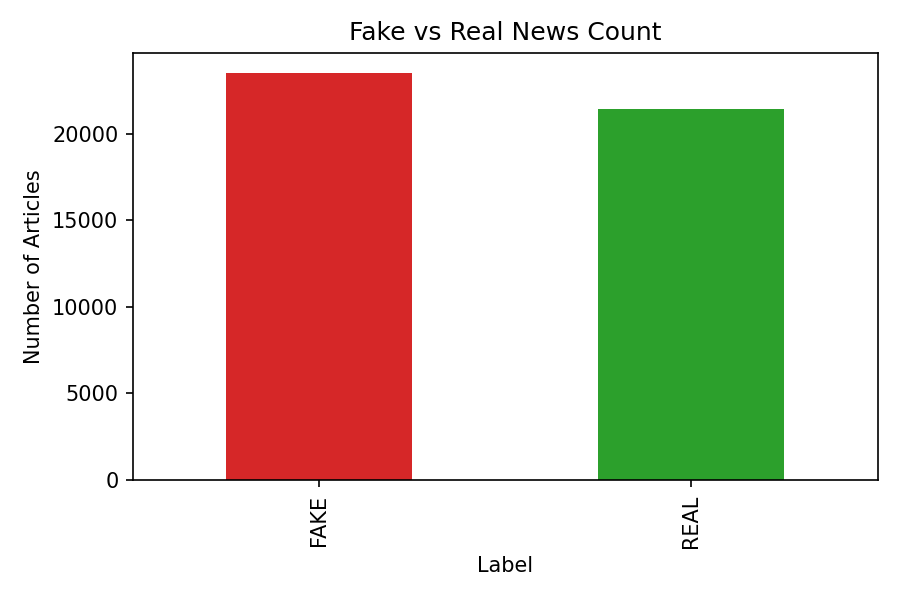

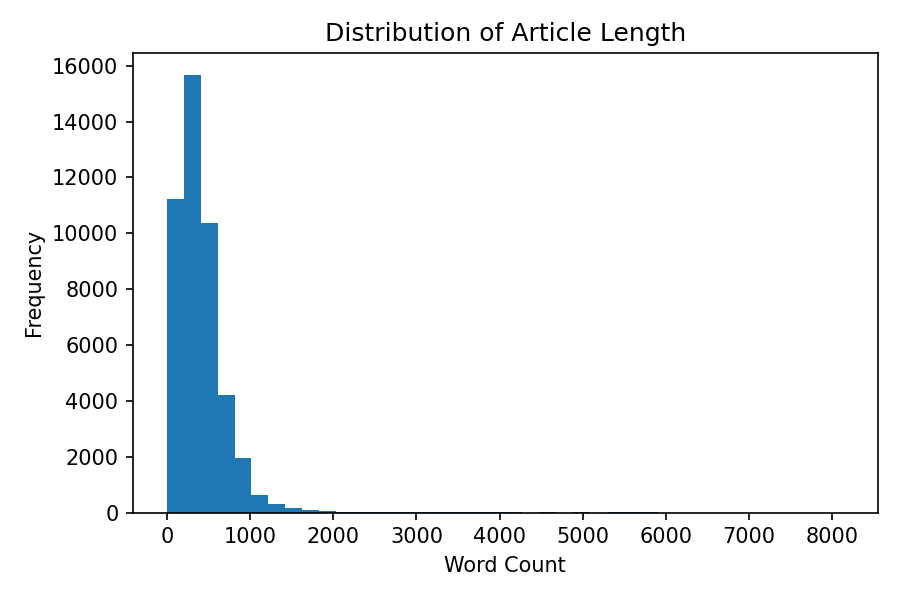

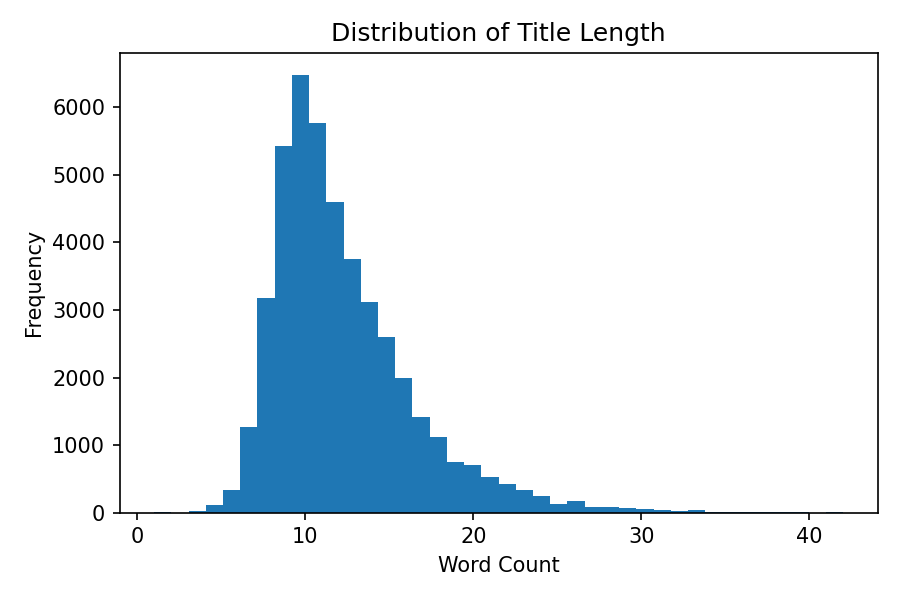

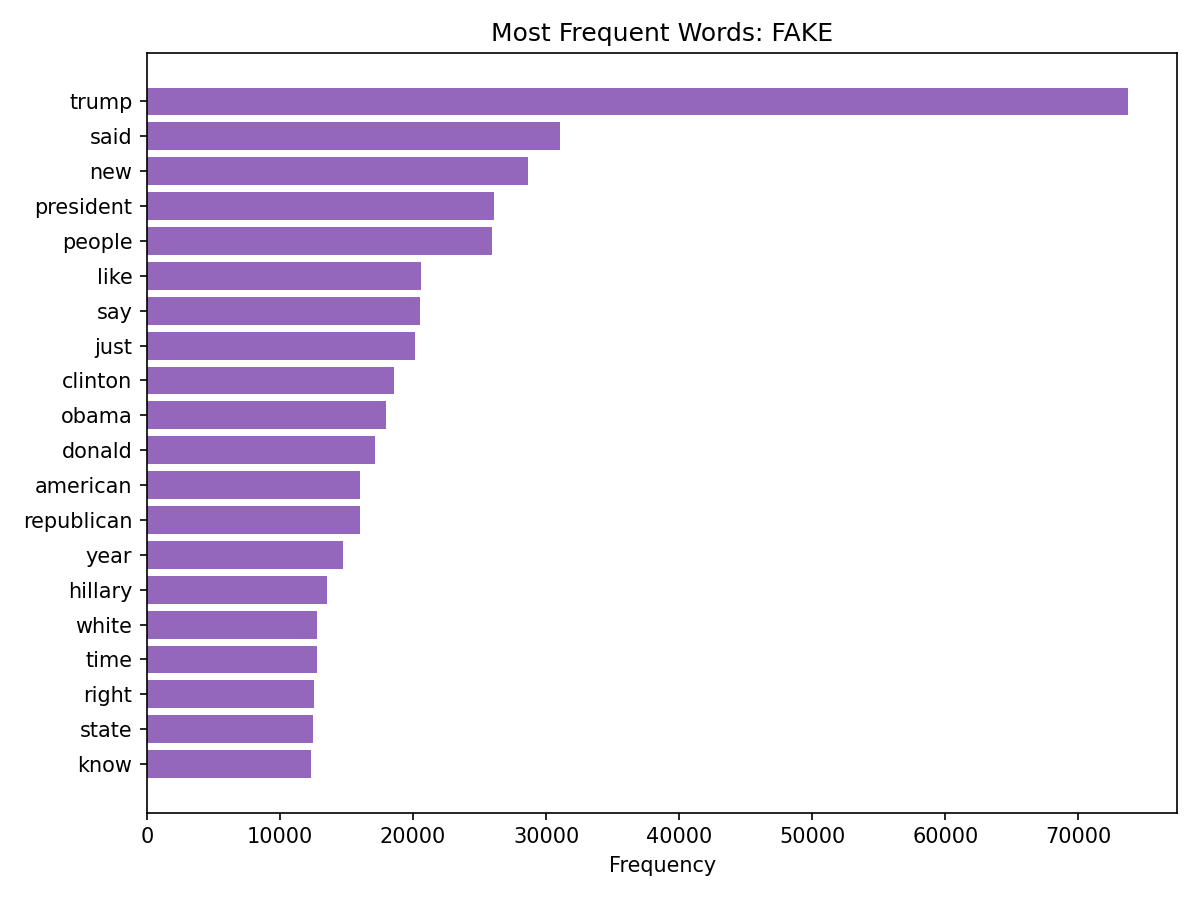

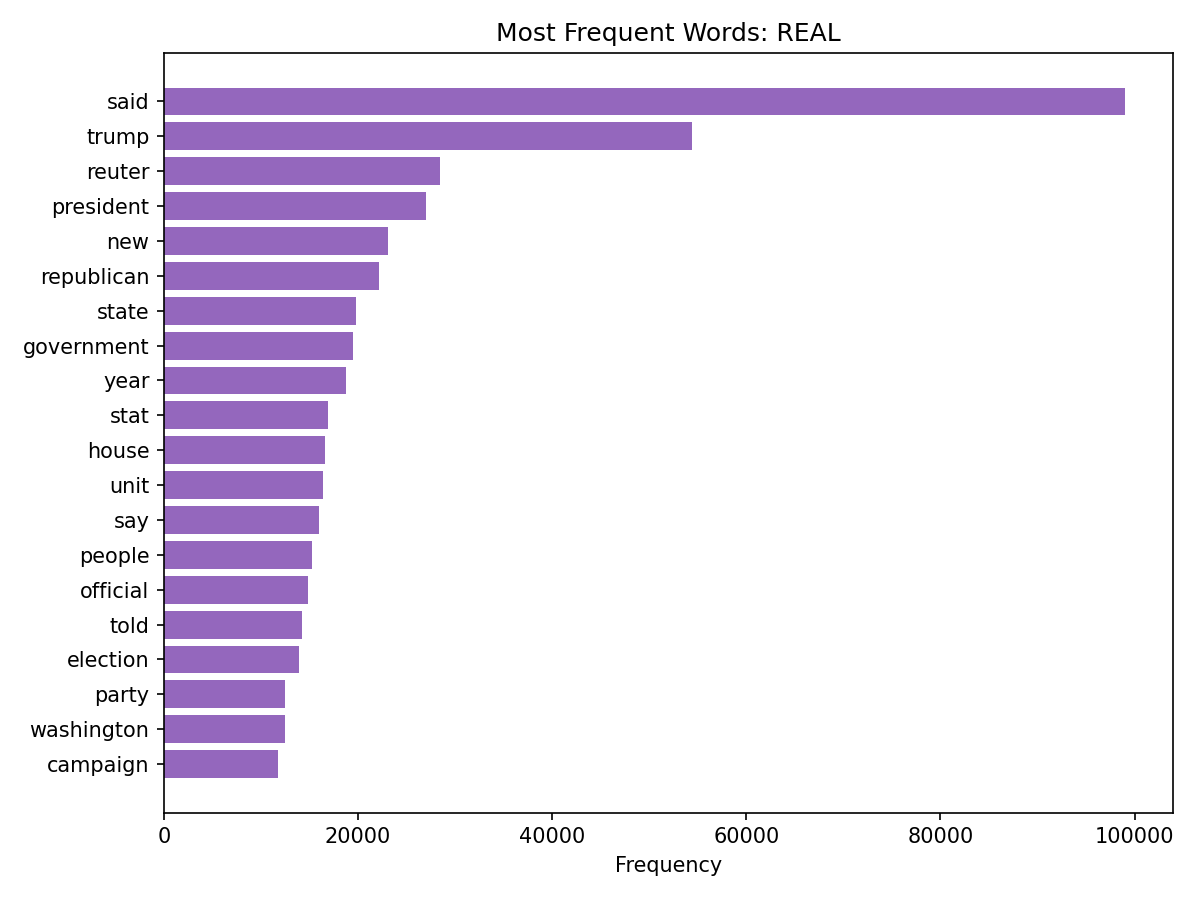

In [4]:
from IPython.display import Image, display

files = [
    "../results/class_distribution.png",
    "../results/article_length_distribution.png",
    "../results/title_length_distribution.png",
    "../results/top_words_FAKE.png",
    "../results/top_words_REAL.png"
]

for file in files:
    display(Image(filename=file))

In [1]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy version:", spacy.__version__)
print("Model loaded successfully!")

spaCy version: 3.8.15
Model loaded successfully!


In [2]:
text = "The scientists were studying fake news stories and reporting their findings."

doc = nlp(text)

for token in doc:
    print(token.text, "→", token.lemma_)

The → the
scientists → scientist
were → be
studying → study
fake → fake
news → news
stories → story
and → and
reporting → report
their → their
findings → finding
. → .


In [1]:
import sys

sys.path.append("../src")

from preprocessing import clean_text

print("Preprocessing module loaded successfully!")

Preprocessing module loaded successfully!


In [2]:
sample = """
BREAKING!!! Scientists <b>SHOCKED</b> after study shows
coffee cures everything!!!
Visit https://example.com/news
"""

print("Original:")
print(sample)

print("\nCleaned:")
print(clean_text(sample))

Original:

BREAKING!!! Scientists <b>SHOCKED</b> after study shows
coffee cures everything!!!
Visit https://example.com/news


Cleaned:
break scientist shock study coffee cure visit


In [4]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy model loaded!")

spaCy model loaded!


In [5]:
text = """
Scientists were studying fake news stories.
Journalists were reporting their findings.
"""

doc = nlp(text)

for token in doc:
    if not token.is_punct and not token.is_space:
        print(f"{token.text:15} → {token.lemma_}")

Scientists      → scientist
were            → be
studying        → study
fake            → fake
news            → news
stories         → story
Journalists     → journalist
were            → be
reporting       → report
their           → their
findings        → finding


In [6]:
import sys
sys.path.append("../src")

from eda import run_eda

print("Final EDA module loaded successfully!")

Final EDA module loaded successfully!


In [1]:
import sys
sys.path.append("../src")

from eda import run_eda

print("Final EDA module loaded successfully!")

Final EDA module loaded successfully!


In [2]:
report = run_eda(
    csv_name="news.csv",
    text_col="text",
    title_col="title",
    label_col="label"
)

print("\nFinal EDA completed!")
print(report)

22:32:38 | INFO    | eda | Loading dataset: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\data\raw\news.csv
22:32:41 | INFO    | eda | Dataset loaded successfully: 44,898 rows
22:32:42 | INFO    | eda | Dataset report: {'n_rows': 44898, 'n_missing_text': 0, 'n_missing_label': 0, 'n_duplicate_rows': 209, 'class_counts': {'FAKE': 23481, 'REAL': 21417}}
22:32:42 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\class_distribution.png
22:32:48 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\article_length_distribution.png
22:32:48 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\results\title_length_distribution.png
22:32:48 | INFO    | eda | Calculating top words for class: FAKE
22:33:01 | INFO    | eda | Saved: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\res


Final EDA completed!
{'n_rows': 44898, 'n_missing_text': 0, 'n_missing_label': 0, 'n_duplicate_rows': 209, 'class_counts': {'FAKE': 23481, 'REAL': 21417}}


In [1]:
import sys
sys.path.append("../src")

from preprocessing import clean_text

sample = """
BREAKING NEWS! Scientists were studying fake news stories
and journalists were reporting their findings.
Visit https://example.com/news
"""

print("Original:")
print(sample)

print("\nCleaned:")
print(clean_text(sample))

22:44:00 | INFO    | preprocessing | Loading spaCy model: en_core_web_sm
22:44:01 | INFO    | preprocessing | spaCy model loaded successfully


Original:

BREAKING NEWS! Scientists were studying fake news stories
and journalists were reporting their findings.
Visit https://example.com/news


Cleaned:
break news scientist study fake news story journalist report finding visit


In [2]:
from train import get_models

models = get_models()

print("Training module loaded successfully!")
print("\nModels:")
for name in models:
    print("-", name)

Training module loaded successfully!

Models:
- Logistic Regression
- Multinomial Naive Bayes
- Linear SVM


In [3]:
import pandas as pd
import sys

sys.path.append("../src")

from train import prepare_data, get_models
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("../data/raw/news.csv")

df_sample = df.sample(n=1000, random_state=42)

print("Sample size:", len(df_sample))
print("Class distribution:")
print(df_sample["label"].value_counts())

X_text, y = prepare_data(
    df_sample,
    title_col="title",
    text_col="text",
    label_col="label"
)

print("\nPreprocessing completed!")
print("Articles after preprocessing:", len(X_text))

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("TF-IDF completed!")
print("Number of features:", X_train.shape[1])

models = get_models()

for name, model in models.items():

    print("\n" + "="*50)
    print(name)
    print("="*50)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions,
        pos_label="FAKE",
        zero_division=0
    )
    recall = recall_score(
        y_test, predictions,
        pos_label="FAKE",
        zero_division=0
    )
    f1 = f1_score(
        y_test, predictions,
        pos_label="FAKE",
        zero_division=0
    )

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

print("\nSmall-scale training test completed successfully! 🎉")

22:45:46 | INFO    | train | Rows after cleaning duplicates/missing values: 985
22:45:46 | INFO    | train | Starting spaCy NLP preprocessing...
22:45:46 | INFO    | preprocessing | Starting spaCy preprocessing for 985 documents...


Sample size: 1000
Class distribution:
label
FAKE    507
REAL    493
Name: count, dtype: int64


22:47:01 | INFO    | preprocessing | spaCy preprocessing completed successfully.
22:47:01 | INFO    | train | Documents remaining after NLP preprocessing: 985



Preprocessing completed!
Articles after preprocessing: 985
TF-IDF completed!
Number of features: 5000

Logistic Regression
Accuracy : 0.9239
Precision: 0.9462
Recall   : 0.8980
F1 Score : 0.9215

Multinomial Naive Bayes
Accuracy : 0.8985
Precision: 0.9062
Recall   : 0.8878
F1 Score : 0.8969

Linear SVM
Accuracy : 0.9594
Precision: 0.9891
Recall   : 0.9286
F1 Score : 0.9579

Small-scale training test completed successfully! 🎉


In [4]:
import sys
sys.path.append("../src")

from train import main

results, best_model = main(
    csv_name="news.csv",
    title_col="title",
    text_col="text",
    label_col="label"
)

print("\n==============================")
print("FINAL MODEL COMPARISON")
print("==============================")
print(results)

print("\nBEST MODEL:")
print(best_model)

22:55:34 | INFO    | train | Loading dataset: C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\data\raw\news.csv
22:55:36 | INFO    | train | Dataset loaded: 44,898 rows
22:55:37 | INFO    | train | Rows after cleaning duplicates/missing values: 38,646
22:55:37 | INFO    | train | Starting spaCy NLP preprocessing...
22:55:37 | INFO    | preprocessing | Starting spaCy preprocessing for 38,646 documents...
23:40:36 | INFO    | preprocessing | spaCy preprocessing completed successfully.
23:40:37 | INFO    | train | Documents remaining after NLP preprocessing: 38,641
23:40:39 | INFO    | train | Classes: ['FAKE', 'REAL']
23:40:39 | INFO    | train | Final training dataset: 38,641 documents
23:40:39 | INFO    | train | Training samples: 30,912
23:40:39 | INFO    | train | Testing samples: 7,729
23:40:39 | INFO    | train | Creating TF-IDF features...
23:41:32 | INFO    | train | TF-IDF training matrix shape: (30912, 5000)
23:41:32 | INFO    | train | TF-IDF testin


FINAL MODEL COMPARISON
                         accuracy  precision  recall  f1_score
Logistic Regression        0.9838     0.9839  0.9838    0.9838
Multinomial Naive Bayes    0.9357     0.9357  0.9357    0.9357
Linear SVM                 0.9925     0.9925  0.9925    0.9925

BEST MODEL:
Linear SVM


In [5]:
import sys
sys.path.append("../src")

from predict import predict_news

In [6]:
result = predict_news(
    """
    Scientists have announced a new discovery after conducting
    extensive research at a major university.
    """
)

print(result)

23:47:46 | INFO    | predict | Loaded model: Linear SVM


{'label': 'FAKE', 'confidence': 67.97, 'is_calibrated': False, 'model_used': 'Linear SVM'}


In [7]:
result = predict_news(
    """
    SHOCKING!!! Scientists reveal that drinking coffee gives humans
    superpowers and the government is hiding the truth from everyone!
    """
)

print(result)

{'label': 'FAKE', 'confidence': 86.06, 'is_calibrated': False, 'model_used': 'Linear SVM'}


In [8]:
import pandas as pd

df = pd.read_csv("../data/raw/news.csv")

sample = df.iloc[0]

text = str(sample["title"]) + " " + str(sample["text"])

result = predict_news(text)

print("Actual label:", sample["label"])
print("Model result:", result)

Actual label: FAKE
Model result: {'label': 'FAKE', 'confidence': 83.66, 'is_calibrated': False, 'model_used': 'Linear SVM'}


In [9]:
import sklearn
print(sklearn.__version__)

1.7.2


In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/news.csv")

sample = df.iloc[0]

print("LABEL:", sample["label"])
print("\nTITLE:")
print(sample["title"])

print("\nARTICLE:")
print(sample["text"])

LABEL: FAKE

TITLE:
 Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing

ARTICLE:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a N

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/news.csv")

df = df.dropna(subset=["text", "label"])
df = df.drop_duplicates(subset=["text"])

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

sample = test_df.sample(1).iloc[0]

article = str(sample["title"]) + "\n\n" + str(sample["text"])

print("ACTUAL LABEL:", sample["label"])
print("\nCOPY THIS INTO STREAMLIT:\n")
print(article)

ACTUAL LABEL: FAKE

COPY THIS INTO STREAMLIT:

 Trump’s Leaks To Russia May Well Have Put Individual Lives In Serious Danger

Trump s ignorance, incompetence, and ego are putting intelligence agents at risk.It won t come as any surprise that international espionage is a complicated, high-stakes affair. At any given time, agents from countries all around the world are embedded with ISIS and other terrorist groups, secretly reporting back to their superiors in order to ensure that America and her allies have the latest intelligence. As the New York Times and Addicting Info have reported, the intelligence that President Trump shared with the Russians came from Israeli sources. That s a problem.Iran is one of Israel s greatest enemies and one of Russia s biggest allies. They certainly have an interest in learning everything they can about Israeli intelligence assets. And now, thanks to Donald Trump s startling incompetence, their Russian allies are free to tell them everything they know.Th

In [8]:
import pandas as pd
import sys

sys.path.append("../src")

from preprocessing import clean_text

df = pd.read_csv("../data/raw/news.csv")

df = df.dropna(subset=["title", "text", "label"])

sample = df.sample(n=1).iloc[0]

title = str(sample["title"])
article = str(sample["text"])

original_text = title + " " + article

processed_text = clean_text(original_text)

print("=" * 80)
print("RANDOM ARTICLE FROM DATASET")
print("=" * 80)

print("\nACTUAL LABEL:", sample["label"])

print("\nTITLE:")
print(title)

print("\nARTICLE:")
print(article)

print("\n" + "=" * 80)
print("PREPROCESSED + LEMMATIZED TEXT")
print("=" * 80)

print(processed_text)

print("\n" + "=" * 80)

RANDOM ARTICLE FROM DATASET

ACTUAL LABEL: FAKE

TITLE:
BREAKING: SECRET SERVICE Takes Action After White House Intruder Got too Close For Comfort [Video]

ARTICLE:
The Secret Service fired two uniformed division officers who were involved in the March 10th intrusion when Jonathan Tran jumped the White House fence and wandered the grounds for 16 minutes, even getting close to the White House s windows and doors:ALARM TURNED OFF: Shocking Details on WHITE HOUSE Fence Jumper:  It was even worse than I thought Secret Service personnel removed the alarm sensors along an area of fence line when the agency raised its height in response to previous fence-jumping incidents as a way to make it harder to scale. Ironically, the very effort to prevent fence jumping appears to have permitted a particularly egregious intrusion.One source said superiors in the Uniformed Division told Secret Service personnel to remove the sensors and piece them together for use elsewhere. They were never replaced.The

In [10]:
import pandas as pd

df = pd.read_csv("../data/raw/news.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df["label"].value_counts())

(44898, 5)
['title', 'text', 'subject', 'date', 'label']
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date label  
0  December 31, 2017  FAKE  
1  December 31, 2017  FAKE  
2  December 30, 2017  FAKE  
3  December 29, 2017  FAKE  
4  December 25, 2017  FAKE  
label
FAKE    23481
REAL    21417
Name: count, 

In [13]:
import pandas as pd

train = pd.read_csv("../data/processed/train.csv")
val = pd.read_csv("../data/processed/val.csv")
test = pd.read_csv("../data/processed/test.csv")

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))
print("Total:", len(train) + len(val) + len(test))

Train: 31284
Validation: 3910
Test: 3911
Total: 39105


In [3]:
import os
import json
import pickle
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

MODEL_DIR = os.path.join("..", "models", "bilstm_artifacts")

MODEL_PATH = os.path.join(MODEL_DIR, "bilstm_model.keras")
TOKENIZER_PATH = os.path.join(MODEL_DIR, "tokenizer.pkl")
METADATA_PATH = os.path.join(MODEL_DIR, "metadata.json")


print("=" * 60)
print("CHECKING BiLSTM ARTIFACTS")
print("=" * 60)

print("\nCurrent working directory:")
print(os.getcwd())

print("\nChecking files:")

for path in [MODEL_PATH, TOKENIZER_PATH, METADATA_PATH]:
    print(
        "✓" if os.path.exists(path) else "✗",
        path,
        "->",
        os.path.exists(path)
    )


if not all(
    os.path.exists(p)
    for p in [MODEL_PATH, TOKENIZER_PATH, METADATA_PATH]
):
    raise FileNotFoundError(
        "\nBiLSTM artifact files were not found.\n"
        "Expected location:\n"
        "../models/bilstm_artifacts/"
    )


print("\nLoading BiLSTM model...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✓ BiLSTM model loaded successfully")


print("Loading tokenizer...")

with open(TOKENIZER_PATH, "rb") as f:
    tokenizer = pickle.load(f)

print("✓ Tokenizer loaded successfully")


print("Loading metadata...")

with open(METADATA_PATH, "r") as f:
    metadata = json.load(f)

print("✓ Metadata loaded successfully")


print("\n" + "=" * 60)
print("BILSTM MODEL INFORMATION")
print("=" * 60)

print("Model type       :", metadata["model_type"])
print("Max sequence len :", metadata["max_len"])
print("Vocabulary size  :", metadata["vocab_size"])
print("Embedding dim    :", metadata["embedding_dim"])
print("LSTM units       :", metadata["lstm_units"])
print("Dropout rate     :", metadata["dropout_rate"])
print("Dense units      :", metadata["dense_units"])
print("Positive label   :", metadata["pos_label"])
print("Classes          :", metadata["classes"])

print("\n" + "=" * 60)
print("TRAINING METRICS")
print("=" * 60)

metrics = metadata["metrics"]

print("Accuracy         :", metrics["accuracy"])
print("Precision        :", metrics["precision"])
print("Recall           :", metrics["recall"])
print("F1 Score         :", metrics["f1_score"])
print("Training time    :", metrics["training_time_seconds"], "seconds")
print("Epochs run       :", metrics["epochs_run"])
print("Trainable params :", metrics["trainable_params"])

print("\n" + "=" * 60)
print("✓ BILSTM ARTIFACTS LOADED SUCCESSFULLY")
print("=" * 60)

CHECKING BiLSTM ARTIFACTS

Current working directory:
C:\Users\Tanmay Agarwal\Documents\fake-news-detector (1)\fake-news-detector\notebooks

Checking files:
✓ ..\models\bilstm_artifacts\bilstm_model.keras -> True
✓ ..\models\bilstm_artifacts\tokenizer.pkl -> True
✓ ..\models\bilstm_artifacts\metadata.json -> True

Loading BiLSTM model...
✓ BiLSTM model loaded successfully
Loading tokenizer...
✓ Tokenizer loaded successfully
Loading metadata...
✓ Metadata loaded successfully

BILSTM MODEL INFORMATION
Model type       : BiLSTM
Max sequence len : 512
Vocabulary size  : 20000
Embedding dim    : 128
LSTM units       : 64
Dropout rate     : 0.5
Dense units      : 32
Positive label   : FAKE
Classes          : ['FAKE', 'REAL']

TRAINING METRICS
Accuracy         : 0.9992329327537715
Precision        : 0.9988839285714286
Recall           : 0.9994416527079844
F1 Score         : 0.999162712810494
Training time    : 227.87881994247437 seconds
Epochs run       : 6
Trainable params : 2662977

✓ BILST

In [4]:


import re
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences


def light_clean(text):
    """
    Same basic cleaning approach used before prediction.
    """

    text = str(text)

    
    text = text.lower()

    
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    
    text = re.sub(r"<.*?>", " ", text)

    
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    
    text = re.sub(r"\s+", " ", text).strip()

    return text


def predict_bilstm(text):
    """
    Predict whether a news article is FAKE or REAL.
    """


    cleaned_text = light_clean(text)

    if cleaned_text == "":
        return {
            "label": "UNKNOWN",
            "confidence": 0.0
        }


    sequence = tokenizer.texts_to_sequences([cleaned_text])

    padded = pad_sequences(
        sequence,
        maxlen=metadata["max_len"],
        padding="post",
        truncating="post"
    )


    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )


    positive_label = metadata["pos_label"]

    classes = metadata["classes"]

    negative_label = next(
        c for c in classes
        if c != positive_label
    )

    if probability >= 0.5:

        label = positive_label
        confidence = probability

    else:

        label = negative_label
        confidence = 1 - probability


    return {
        "label": label,
        "confidence": round(confidence * 100, 2)
    }



news_text = """
The government announced a new economic policy today
that is expected to significantly increase employment
and support economic growth over the next five years.
"""

result = predict_bilstm(news_text)

print("=" * 50)
print("BILSTM PREDICTION")
print("=" * 50)

print("Prediction :", result["label"])
print("Confidence :", result["confidence"], "%")
print("Model      : BiLSTM")

BILSTM PREDICTION
Prediction : FAKE
Confidence : 100.0 %
Model      : BiLSTM


In [8]:
import pandas as pd
import random
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import pad_sequences


df = pd.read_csv("../data/raw/news.csv")

df = df.dropna(subset=["text", "label"])
df = df.drop_duplicates(subset=["text"])


train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Total articles :", len(df))
print("Test articles  :", len(test_df))


sample = test_df.sample(1).iloc[0]

title = str(sample["title"])
text = str(sample["text"])

article = title + "\n\n" + text

original_label = str(sample["label"]).upper()


print("\n" + "=" * 60)
print("RANDOM TEST ARTICLE")
print("=" * 60)

print("\nORIGINAL LABEL:", original_label)

print("\nTITLE:")
print(title)

print("\nARTICLE:")
print(text[:3000])


cleaned_article = light_clean(article)


sequence = tokenizer.texts_to_sequences([cleaned_article])

padded_sequence = pad_sequences(
    sequence,
    maxlen=metadata["max_len"],
    padding="post",
    truncating="post"
)


prediction_probability = float(
    model.predict(padded_sequence, verbose=0)[0][0]
)


positive_label = metadata["pos_label"]
classes = metadata["classes"]

negative_label = next(
    c for c in classes
    if c != positive_label
)

if prediction_probability >= 0.5:

    predicted_label = positive_label
    confidence = prediction_probability

else:

    predicted_label = negative_label
    confidence = 1 - prediction_probability

predicted_label = str(predicted_label).upper()


print("\n" + "=" * 60)
print("BILSTM PREDICTION")
print("=" * 60)

print("\nOriginal Label :", original_label)
print("Predicted Label:", predicted_label)
print("Confidence     :", round(confidence * 100, 2), "%")


print("\n" + "=" * 60)

if predicted_label == original_label:
    print("✓ RESULT: CORRECT PREDICTION")
else:
    print("✗ RESULT: MISCLASSIFIED")

print("=" * 60)

Total articles : 38646
Test articles  : 7730

RANDOM TEST ARTICLE

ORIGINAL LABEL: FAKE

TITLE:
 John Kasich Decides To Say EVEN WORSE Things About Rape Victims (VIDEO)

ARTICLE:
There was once a time that John Kasich seemed like the only sane, somewhat reasonable Republican candidate in the presidential race, but those days are long gone. Kasich is starting to sound more and more like Trump and Cruz as time goes on.It was just a few days ago that Kasich said that if women wanted to avoid being raped, they should just not go to parties where there is alcohol. He of course experienced tons of backlash for that comment, but instead of apologizing and admitting that it was a victim-blaming, insensitive remark, he s doubled down instead.In a Sunday morning interview on CNN s State of the Union, Kasich made an attempt to rectify his controversial comments, and ended up making it much worse. In trying to explain his misogynistic reasoning, Kasich said that having alcohol at a party makes it 

In [9]:
%%writefile ../src/text_light_clean.py

import re


def light_clean(text: str) -> str:
    """
    Lightweight text cleaning used before BiLSTM prediction.
    """

    if text is None:
        return ""

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Keep letters, numbers and whitespace
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

Writing ../src/text_light_clean.py


In [10]:
import os

print(os.path.exists("../src/text_light_clean.py"))

True


In [11]:
import sys
import os

sys.path.insert(0, "../src")

from predict_bilstm import predict_news_bilstm

result = predict_news_bilstm(
    "John Kasich discusses the political controversy surrounding his comments"
)

print(result)

18:31:47 | INFO    | predict_bilstm | Loaded BiLSTM model (max_len=512)


{'label': 'FAKE', 'confidence': 100.0, 'is_calibrated': False, 'model_used': 'BiLSTM'}


In [1]:


import os
import sys
import random
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


PROJECT_ROOT = os.path.abspath("..")
SRC_DIR = os.path.join(PROJECT_ROOT, "src")

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from predict import predict_news
from predict_bilstm import predict_news_bilstm


DATA_PATH = "../data/raw/news.csv"

df = pd.read_csv(DATA_PATH)

df = df.dropna(subset=["text", "label"])
df = df.drop_duplicates(subset=["text"])

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Total articles:", len(df))


train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training articles:", len(train_df))
print("Test articles:", len(test_df))


sample_df = test_df.sample(
    n=10,
    random_state=None
).reset_index(drop=True)

print("\nSelected 10 random test articles.")


results = []

print("\n")
print("=" * 70)
print("RUNNING 10 RANDOM TEST ARTICLES")
print("=" * 70)


for i, row in sample_df.iterrows():


    title = str(row.get("title", ""))
    text = str(row["text"])

    article = title + "\n\n" + text

    actual_label = str(row["label"]).upper()


    svm_result = predict_news(article)

    svm_prediction = str(svm_result["label"]).upper()
    svm_confidence = float(svm_result["confidence"])


    bilstm_result = predict_news_bilstm(article)

    bilstm_prediction = str(bilstm_result["label"]).upper()
    bilstm_confidence = float(bilstm_result["confidence"])


    svm_correct = svm_prediction == actual_label
    bilstm_correct = bilstm_prediction == actual_label


    results.append({
        "Test": i + 1,
        "Actual": actual_label,
        "SVM Prediction": svm_prediction,
        "BiLSTM Prediction": bilstm_prediction,
        "SVM Confidence (%)": svm_confidence,
        "BiLSTM Confidence (%)": bilstm_confidence,
        "SVM Correct": svm_correct,
        "BiLSTM Correct": bilstm_correct,
        "Models Agree": svm_prediction == bilstm_prediction
    })


    print("\n" + "-" * 70)
    print(f"TEST ARTICLE {i + 1}")
    print("-" * 70)

    print("Title:")
    print(title[:250])

    print("\nActual Label     :", actual_label)

    print("\nSVM + TF-IDF")
    print("Prediction       :", svm_prediction)
    print("Confidence       :", f"{svm_confidence:.2f}%")
    print("Correct?         :", "YES" if svm_correct else "NO")

    print("\nBiLSTM")
    print("Prediction       :", bilstm_prediction)
    print("Confidence       :", f"{bilstm_confidence:.2f}%")
    print("Correct?         :", "YES" if bilstm_correct else "NO")

    print("\nModels Agree?    :", "YES" if svm_prediction == bilstm_prediction else "NO")


results_df = pd.DataFrame(results)


print("\n")
print("=" * 70)
print("10-ARTICLE TEST RESULTS")
print("=" * 70)

display(results_df)


actual = results_df["Actual"]

svm_pred = results_df["SVM Prediction"]
bilstm_pred = results_df["BiLSTM Prediction"]


svm_accuracy = accuracy_score(actual, svm_pred)

svm_precision = precision_score(
    actual,
    svm_pred,
    pos_label="FAKE",
    zero_division=0
)

svm_recall = recall_score(
    actual,
    svm_pred,
    pos_label="FAKE",
    zero_division=0
)

svm_f1 = f1_score(
    actual,
    svm_pred,
    pos_label="FAKE",
    zero_division=0
)


bilstm_accuracy = accuracy_score(actual, bilstm_pred)

bilstm_precision = precision_score(
    actual,
    bilstm_pred,
    pos_label="FAKE",
    zero_division=0
)

bilstm_recall = recall_score(
    actual,
    bilstm_pred,
    pos_label="FAKE",
    zero_division=0
)

bilstm_f1 = f1_score(
    actual,
    bilstm_pred,
    pos_label="FAKE",
    zero_division=0
)


print("\n")
print("=" * 70)
print("MODEL PERFORMANCE ON 10 RANDOM TEST ARTICLES")
print("=" * 70)

print("\nSVM + TF-IDF")
print("-" * 30)
print(f"Accuracy  : {svm_accuracy:.4f} ({svm_accuracy * 100:.2f}%)")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")

print("\nBiLSTM")
print("-" * 30)
print(f"Accuracy  : {bilstm_accuracy:.4f} ({bilstm_accuracy * 100:.2f}%)")
print(f"Precision : {bilstm_precision:.4f}")
print(f"Recall    : {bilstm_recall:.4f}")
print(f"F1 Score  : {bilstm_f1:.4f}")


svm_correct_count = results_df["SVM Correct"].sum()
bilstm_correct_count = results_df["BiLSTM Correct"].sum()

agreement_count = results_df["Models Agree"].sum()

print("\n")
print("=" * 70)
print("ADDITIONAL RESULTS")
print("=" * 70)

print(
    f"\nSVM correct predictions    : "
    f"{svm_correct_count}/10"
)

print(
    f"BiLSTM correct predictions : "
    f"{bilstm_correct_count}/10"
)

print(
    f"Model agreement             : "
    f"{agreement_count}/10"
)

print(
    f"Model disagreement          : "
    f"{10 - agreement_count}/10"
)


labels = ["FAKE", "REAL"]

svm_cm = confusion_matrix(
    actual,
    svm_pred,
    labels=labels
)

bilstm_cm = confusion_matrix(
    actual,
    bilstm_pred,
    labels=labels
)

print("\n")
print("=" * 70)
print("SVM CONFUSION MATRIX")
print("=" * 70)

print(
    pd.DataFrame(
        svm_cm,
        index=["Actual FAKE", "Actual REAL"],
        columns=["Predicted FAKE", "Predicted REAL"]
    )
)


print("\n")
print("=" * 70)
print("BiLSTM CONFUSION MATRIX")
print("=" * 70)

print(
    pd.DataFrame(
        bilstm_cm,
        index=["Actual FAKE", "Actual REAL"],
        columns=["Predicted FAKE", "Predicted REAL"]
    )
)


print("\n")
print("=" * 70)
print("SVM CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        actual,
        svm_pred,
        labels=labels,
        zero_division=0
    )
)


print("\n")
print("=" * 70)
print("BiLSTM CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        actual,
        bilstm_pred,
        labels=labels,
        zero_division=0
    )
)



comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Correct Predictions"
    ],

    "SVM + TF-IDF": [
        svm_accuracy,
        svm_precision,
        svm_recall,
        svm_f1,
        f"{svm_correct_count}/10"
    ],

    "BiLSTM": [
        bilstm_accuracy,
        bilstm_precision,
        bilstm_recall,
        bilstm_f1,
        f"{bilstm_correct_count}/10"
    ]
})

print("\n")
print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(comparison_df)

18:46:05 | INFO    | preprocessing | Loading spaCy model: en_core_web_sm
18:46:06 | INFO    | preprocessing | spaCy model loaded successfully


DATASET INFORMATION
Total articles: 38646
Training articles: 30916
Test articles: 7730

Selected 10 random test articles.


RUNNING 10 RANDOM TEST ARTICLES


18:46:10 | INFO    | predict | Loaded model: Linear SVM


18:46:22 | INFO    | predict_bilstm | Loaded BiLSTM model (max_len=512)



----------------------------------------------------------------------
TEST ARTICLE 1
----------------------------------------------------------------------
Title:
 Reince Priebus Says We ARE Going Forward With Trump’s COMPLETELY Asinine Terrorism Plan

Actual Label     : FAKE

SVM + TF-IDF
Prediction       : FAKE
Confidence       : 84.23%
Correct?         : YES

BiLSTM
Prediction       : FAKE
Confidence       : 100.00%
Correct?         : YES

Models Agree?    : YES

----------------------------------------------------------------------
TEST ARTICLE 2
----------------------------------------------------------------------
Title:
Britain, EU have very different legal stances on Brexit bill: UK minister

Actual Label     : REAL

SVM + TF-IDF
Prediction       : REAL
Confidence       : 84.58%
Correct?         : YES

BiLSTM
Prediction       : REAL
Confidence       : 100.00%
Correct?         : YES

Models Agree?    : YES

----------------------------------------------------------------------

,Test,Actual,SVM Prediction,BiLSTM Prediction,SVM Confidence (%),BiLSTM Confidence (%),SVM Correct,BiLSTM Correct,Models Agree
0,1,FAKE,FAKE,FAKE,84.23,100.0,True,True,True
1,2,REAL,REAL,REAL,84.58,100.0,True,True,True
2,3,FAKE,FAKE,FAKE,76.52,100.0,True,True,True
3,4,REAL,REAL,REAL,75.63,100.0,True,True,True
4,5,FAKE,FAKE,FAKE,64.34,100.0,True,True,True
5,6,REAL,REAL,REAL,92.65,100.0,True,True,True
6,7,REAL,REAL,REAL,92.38,100.0,True,True,True
7,8,REAL,REAL,REAL,74.14,100.0,True,True,True
8,9,FAKE,FAKE,FAKE,70.96,100.0,True,True,True
9,10,FAKE,FAKE,FAKE,87.02,100.0,True,True,True




MODEL PERFORMANCE ON 10 RANDOM TEST ARTICLES

SVM + TF-IDF
------------------------------
Accuracy  : 1.0000 (100.00%)
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000

BiLSTM
------------------------------
Accuracy  : 1.0000 (100.00%)
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000


ADDITIONAL RESULTS

SVM correct predictions    : 10/10
BiLSTM correct predictions : 10/10
Model agreement             : 10/10
Model disagreement          : 0/10


SVM CONFUSION MATRIX
             Predicted FAKE  Predicted REAL
Actual FAKE               5               0
Actual REAL               0               5


BiLSTM CONFUSION MATRIX
             Predicted FAKE  Predicted REAL
Actual FAKE               5               0
Actual REAL               0               5


SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       1.00      1.00      1.00         5
        REAL       1.00      1.00      1.00         5

    accuracy                 

,Metric,SVM + TF-IDF,BiLSTM
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1 Score,1.0,1.0
4,Correct Predictions,10/10,10/10


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
CUDA: False


In [2]:
import os
import json
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_PATH = "../models/bert/model"
TOKENIZER_PATH = "../models/bert/tokenizer"
METADATA_PATH = "../models/bert/metadata.json"

print("Checking BERT artifacts...")

print("Model:", os.path.exists(MODEL_PATH))
print("Tokenizer:", os.path.exists(TOKENIZER_PATH))
print("Metadata:", os.path.exists(METADATA_PATH))

ModuleNotFoundError: No module named 'transformers'

In [3]:
%pip install transformers datasets accelerate evaluate scikit-learn

   ---------------------------------------- 0.0/11.7 MB ? eta -:--:--
    --------------------------------------- 0.3/11.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.7 MB 2.0 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/11.7 MB 2.0 MB/s eta 0:00:06
   ----- ---------------------------------- 1.6/11.7 MB 2.0 MB/s eta 0:00:06
   ------- -------------------------------- 2.1/11.7 MB 2.0 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/11.7 MB 2.0 MB/s eta 0:00:05
   --------- ------------------------------ 2.9/11.7 MB 2.0 MB/s eta 0:00:05
   ----------- ---------------------------- 3.4/11.7 MB 2.0 MB/s eta 0:00:05
   ------------- -------------------------- 3.9/11.7 MB 2.0 MB/s eta 0:00:04
   --------------- ------------------------ 4.5/11.7 MB 2.1 MB/s eta 0:00:04
   ---------------- ----------------------- 4.7/11.7 MB 2.1 MB/s eta 0:00:04
   ----------------- ---------------------- 5.2/11.7 MB 2.1 MB/s eta 0:00:04
   ----------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.35.1 which is incompatible.


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
CUDA: False


In [2]:
import transformers

print("Transformers:", transformers.__version__)

Transformers: 5.15.1


In [4]:
import os
import json
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification


MODEL_PATH = "../models/bert_artifacts/model"
TOKENIZER_PATH = "../models/bert_artifacts/tokenizer"
METADATA_PATH = "../models/bert_artifacts/metadata.json"

print("Checking BERT artifacts...")

print("Model:", os.path.exists(MODEL_PATH))
print("Tokenizer:", os.path.exists(TOKENIZER_PATH))
print("Metadata:", os.path.exists(METADATA_PATH))

Checking BERT artifacts...
Model: True
Tokenizer: True
Metadata: True


In [5]:
tokenizer_bert = AutoTokenizer.from_pretrained(TOKENIZER_PATH)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
)

model_bert.eval()

with open(METADATA_PATH, "r") as f:
    bert_metadata = json.load(f)

print("\nBERT model loaded successfully!")
print("Model:", bert_metadata["model_type"])
print("Max length:", bert_metadata["max_len"])
print("Classes:", bert_metadata["classes"])
print("Positive label:", bert_metadata["pos_label"])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


BERT model loaded successfully!
Model: distilbert-base-uncased
Max length: 256
Classes: ['FAKE', 'REAL']
Positive label: FAKE


In [6]:
text = """
Scientists have announced a new breakthrough in renewable energy
technology after several years of research.
"""

inputs = tokenizer_bert(
    text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=bert_metadata["max_len"]
)

with torch.no_grad():
    outputs = model_bert(**inputs)

probabilities = torch.softmax(outputs.logits, dim=-1)
prediction = torch.argmax(probabilities, dim=-1).item()

classes = bert_metadata["classes"]

print("Prediction:", classes[prediction])
print("Confidence:", round(probabilities[0][prediction].item() * 100, 2), "%")

Prediction: REAL
Confidence: 98.81 %


In [1]:
import sys
import os

sys.path.append("../src")

from predict_bert import predict_news_bert

print("predict_bert imported successfully!")

predict_bert imported successfully!


In [3]:
test_article = """
WATCH: Trump Gets SKEWERED By Morning Joe For Firing Acting Attorney General Like A True Tyrant

Joe Scarborough says Donald Trump is acting like a dictator because of the way he fired acting Attorney General Sally Yates.Yates stood up to Trump and refused to defend his unconstitutional executive order banning people from entering the United States if they are traveling from seven specific countries in the Middle East and Africa.The order violates constitutional rights and caused worldwide chaos over the weekend while sparking protests and condemnation around the globe. The acting Attorney General, Sally Yates, has betrayed the Department of Justice by refusing to enforce a legal order designed to protect the citizens of the United States,  Trump said in a statement from the White House.  Ms. Yates is an Obama Administration appointee who is weak on borders and very weak on illegal immigration. Trump s words shocked the Morning Joe host, who compared the way Trump fired Yates to how a tyrant would do it. The word  betrayed,  using the word betrayed for somebody, that s frightening,  Scarborough said on Tuesday morning.  That s what an autocrat would use, whoever put that word in there. An autocrat is just another term for  dictator  or  tyrant. Scarborough went on to slam Trump for acting like a petulant child. There are people that can have reasonable differences without saying that, if they don t agree with you, they ve betrayed you. That is frightening, chilling language, whether they had a right to do this or not  But saying somebody  betrayed  the Justice Department because they don t agree with you? Take that to Venezuela, OK? We don t really want to use that sort of language here. It s time for you guys to grow up. Here s the video via YouTube.Apparently, Donald Trump intends to fire anyone in our government who disagrees with him, and that s dangerous.Yates, as acting Attorney General, explained her responsibilities in a letter that makes it clear that she was trying to protect the integrity of the Justice Department by not jumping to defend an order without all the facts. My responsibility is to ensure that the position of the Department of Justice is not only legally defensible, but is informed by our best view of what the law is after consideration of all the facts. In addition, I am responsible for ensuring that the positions we take in court remain consistent with this institution s solemn obligation to always seek justice and stand for what is right. At present, I am not convinced that the defense of the executive order is consistent with these responsibilities nor am I convinced that the executive order is lawful. This is particularly scary because once Trump has full control of the Justice Department he will cripple it and no amount of protests or lawsuits will prevent him from doing so. We may even lose the power to oust Trump via elections. As long as Trump is allowed to solidify his power, no election will ever be fair and free again. And he will use the Justice Department to make sure of it, which means we will have no legal means to save democracy.Featured image via Chip Somodevilla/Getty Images

"""

result = predict_news_bert(test_article)

print("Prediction :", result["label"])
print("Confidence :", result["confidence"], "%")
print("Model      :", result["model_used"])

Prediction : FAKE
Confidence : 100.0 %
Model      : distilbert-base-uncased


In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/news.csv")

df = df.dropna(subset=["text", "label"])
df = df.drop_duplicates(subset=["text"])

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

sample = test_df.sample(1).iloc[0]

article = str(sample["title"]) + "\n\n" + str(sample["text"])

print("ACTUAL LABEL:", sample["label"])
print("\nCOPY THIS INTO STREAMLIT:\n")
print(article)

ACTUAL LABEL: REAL

COPY THIS INTO STREAMLIT:

Puerto Rico governor hopes for 'open dialogue' with Mnuchin

(Reuters) - Puerto Rico Governor Ricardo Rossello said on Friday he was “committed to establishing a working relationship” and fostering “open dialogue” with U.S. Treasury Secretary Steven Mnuchin, after the two met in Washington.  Rossello, who took office on Jan. 2, met with Mnuchin to discuss his efforts to “put Puerto Rico’s financial house in order,” a statement from the governor’s office said. Rossello has signed more than 20 bills and executive orders aimed at cutting spending and fostering economic growth, but Puerto Rico faces a long haul out of an economic crisis characterized by a 45 percent poverty rate, near-insolvent public pensions and healthcare systems, and almost $70 billion in debt.  Under former President Barack Obama, the Treasury took a hands-on approach in Puerto Rico, working with federal lawmakers on legislation aimed at giving the U.S. territory a way to